# Bank Marketing: who subscribes to a term deposit?

A Portuguese bank ran phone campaigns to sell term deposits. Only about **1 in 9** contacted clients said yes,
so most calls were wasted. This notebook asks two questions:

1. **Which client groups and campaign conditions go with a higher subscription rate?**
2. **Can a model rank clients so the bank calls the most promising ones first?**

Data: `bank-additional.csv` from the [UCI Bank Marketing dataset](https://archive.ics.uci.edu/dataset/222/bank+marketing)
(Moro, Cortez & Rita, 2014), a random 10% sample (4,119 clients) of the full dataset.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

import bank_analysis as ba

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
BLUE, GREY = "#2F5D8A", "#9AA5B1"

def save(fig, name):
    fig.savefig(f"images/{name}.png", bbox_inches="tight", dpi=130)

## 1. Data quality

Missing values are coded as `"unknown"`. The table shows how many there are in each column.

In [2]:
raw = ba.load_raw()
print(f"{len(raw)} clients, {raw.shape[1]} columns")
ba.missing_report(raw)

4119 clients, 21 columns


,missing,percent
default,803,19.5
education,167,4.1
housing,105,2.5
loan,105,2.5
job,39,0.9
marital,11,0.3


## 2. Cleaning

Each step and the reason for it is written in `clean()` in `bank_analysis.py`. In short:
rows with a few missing fields are dropped or filled; the 20% unknown `default` answers are kept as their own group;
and **`duration` is removed**, because the length of a call is only known after the call is over,
so it cannot be used to decide whom to call.

In [3]:
df, log = ba.clean(raw)
for step in log:
    print("-", step)
print(f"\nClean table: {df.shape[0]} clients. Overall subscription rate: {100 * df['subscribed'].mean():.1f}%")

- Dropped 144 rows with unknown job, housing or loan (3.5% of the data).
- Filled 11 unknown 'marital' values with the most frequent value 'married'.
- Filled 153 unknown 'education' values with the most frequent value 'university.degree'.
- Kept 761 unknown 'default' values as their own category.
- Replaced pdays with a 0/1 flag 'previously_contacted' and removed 'duration' (only known after the call).

Clean table: 3975 clients. Overall subscription rate: 11.0%


## 3. Exploratory analysis

Every chart shows the **subscription rate** of a group, with the overall average as a dashed line.
The number above each bar is the number of clients in that group: small groups give less reliable rates.

In [4]:
g = ba.add_groups(df)
avg = 100 * df["subscribed"].mean()

def rate_chart(col, title, order=None, horizontal=False, name=None):
    t = ba.rate_by(g, col, order)
    if horizontal:
        t = t.sort_values("rate")
    fig, ax = plt.subplots(figsize=(7, 4.2 if not horizontal else 0.35 * len(t) + 1.2))
    labels = [str(i) for i in t.index]
    if horizontal:
        ax.barh(labels, t["rate"], color=BLUE)
        ax.axvline(avg, ls="--", color=GREY)
        for i, (r, n) in enumerate(zip(t["rate"], t["clients"])):
            ax.text(r + 0.5, i, f"{r:.0f}%  (n={n})", va="center", fontsize=8)
        ax.set_xlabel("Subscription rate (%)")
    else:
        ax.bar(labels, t["rate"], color=BLUE)
        ax.axhline(avg, ls="--", color=GREY)
        for i, (r, n) in enumerate(zip(t["rate"], t["clients"])):
            ax.text(i, r + 0.8, f"{r:.0f}%\nn={n}", ha="center", fontsize=8)
        ax.set_ylabel("Subscription rate (%)")
        ax.set_ylim(0, t["rate"].max() * 1.25)
    ax.set_title(title)
    plt.show()
    if name:
        save(fig, name)
    return t

### When were clients called?

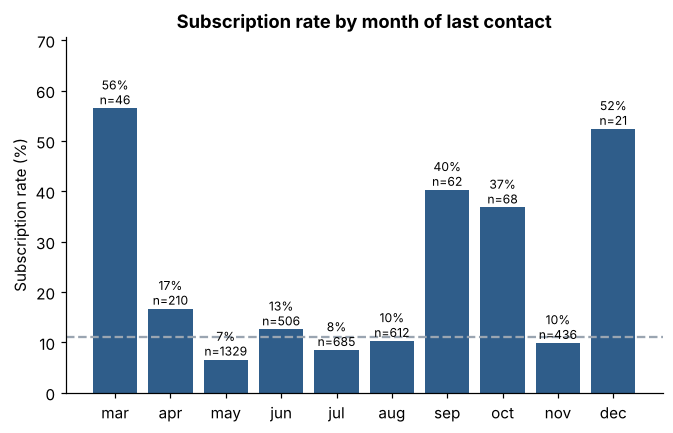

In [5]:
rate_chart("month", "Subscription rate by month of last contact", order=ba.MONTH_ORDER, name="rate_by_month");

May had by far the most calls but one of the lowest rates (about 7%). March, September, October and December
show rates of 37-57%, but on few calls each, so these rates are less certain.

### Does calling the same client again help?

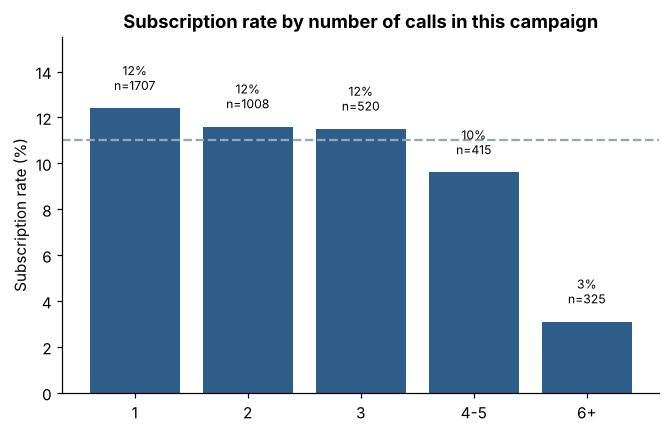

In [6]:
rate_chart("contacts_in_campaign", "Subscription rate by number of calls in this campaign", name="rate_by_contacts");

The rate falls as the number of calls grows: about 12% after one call, about 3% after six or more.
Repeated calls to the same client bring diminishing returns.

### Previous campaigns

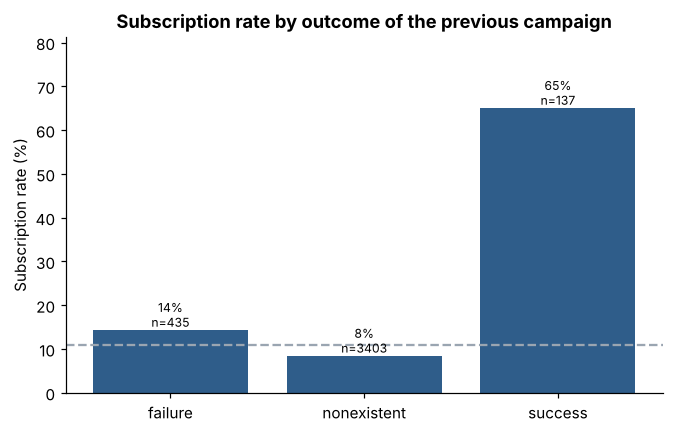

In [7]:
rate_chart("poutcome", "Subscription rate by outcome of the previous campaign", name="rate_by_previous");

Clients who said yes in a previous campaign subscribed again in about 65% of cases,
six times the average. This small group (137 clients) is the most valuable to call.

### Who are the clients?

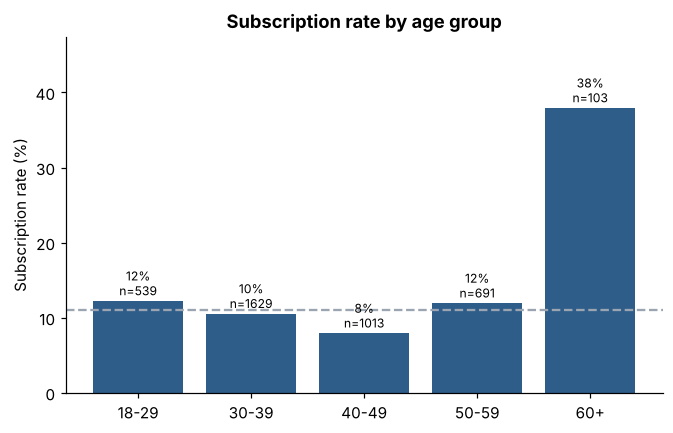

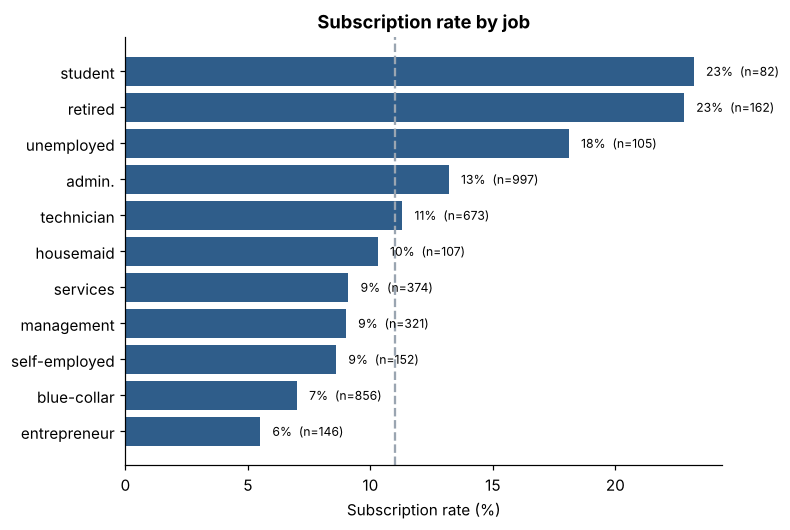

In [8]:
rate_chart("age_group", "Subscription rate by age group", name="rate_by_age")
rate_chart("job", "Subscription rate by job", horizontal=True, name="rate_by_job");

Clients aged 60+, students and retired clients subscribe more often; blue-collar workers and entrepreneurs less.
Contact type also matters: mobile phone (`cellular`) contacts subscribed at about 14%, landline at about 5%.

In [9]:
ba.rate_by(g, "contact")

,clients,rate
contact,,
cellular,2569,14.2
telephone,1406,5.2


## 4. Predicting who will subscribe

**Setup.**
* Features: client profile, campaign details and the five economic indicators. `duration` is excluded (see Cleaning).
* Categorical columns are one-hot encoded and numeric columns standardised. Standardising matters for KNN,
  which compares clients by distance: without it, a large-scale column such as `nr.employed` (around 5,000)
  would dominate small-scale ones such as `campaign`.
* **Evaluation: 5-fold stratified cross-validation.** Every client is scored by a model that never saw them.
  With only about 440 subscribers, a single train/test split would leave too few positive cases for a stable result.

**Why accuracy is not enough.** 89% of clients said no, so a "model" that always answers no is already 89% accurate
and finds no subscriber at all. The useful measures are **recall** (share of real subscribers found) and
**precision** (share of predicted subscribers who really subscribed).

In [10]:
X, y = ba.features_target(df)
results, probas = ba.compare_models(X, y)
results

,Accuracy,Precision (yes),Recall (yes),F1 (yes),ROC AUC
Baseline (always 'no'),0.890,0.000,0.000,0.000,0.500
KNN (k=6),0.890,0.500,0.299,0.374,0.700
Logistic regression (balanced),0.824,0.338,0.619,0.437,0.753


* **KNN** has the same accuracy as the baseline (89%) and finds only about 30% of subscribers.
* **Logistic regression with balanced class weights** finds about 62% of subscribers. It is less accurate overall,
  because it also flags more clients who say no: about one in three flagged clients really subscribes.
  For a bank this is usually the better trade-off, since a missed subscriber costs more than an extra call.

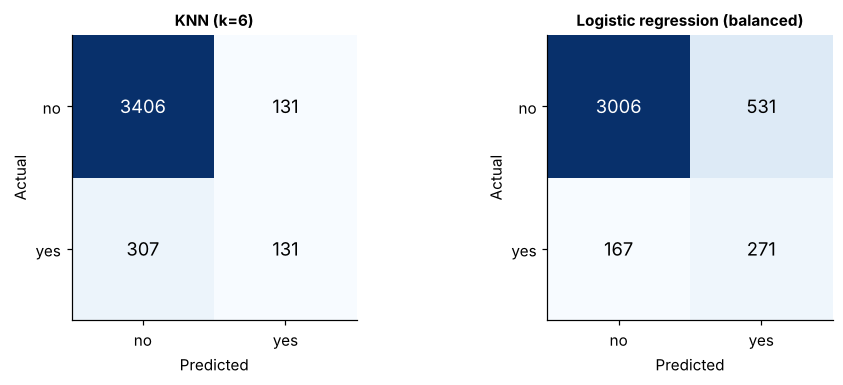

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, name in zip(axes, ["KNN (k=6)", "Logistic regression (balanced)"]):
    cm = confusion_matrix(y, (probas[name] >= 0.5).astype(int))
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in pd.DataFrame(cm).stack().items():
        ax.text(j, i, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=12)
    ax.set_xticks([0, 1], ["no", "yes"]); ax.set_yticks([0, 1], ["no", "yes"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()
save(fig, "confusion_matrices")

## 5. What this means for the campaign

A model is most useful here as a **ranking**: score every client, then call the highest-scored first.
The table shows what happens if the bank calls only the top part of the list.

In [12]:
best = "Logistic regression (balanced)"
ba.gains(y, probas[best])

,Clients called,Calls,Subscribers found,Share of all subscribers,Success rate of calls (%)
0,top 10%,398,190,43.4,47.7
1,top 20%,795,271,61.9,34.1
2,top 30%,1192,291,66.4,24.4
3,top 50%,1988,328,74.9,16.5


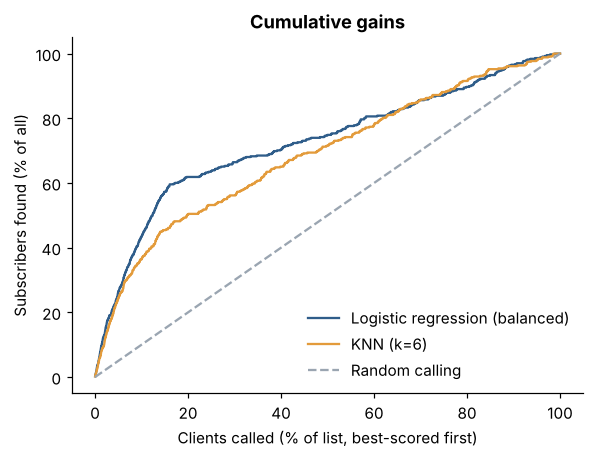

In [13]:
fig, ax = plt.subplots(figsize=(6, 4.2))
for name, color in [(best, BLUE), ("KNN (k=6)", "#E39B3B")]:
    xs, ys = ba.gains_curve(y, probas[name])
    ax.plot(100 * xs, 100 * ys, color=color, label=name)
ax.plot([0, 100], [0, 100], ls="--", color=GREY, label="Random calling")
ax.set_xlabel("Clients called (% of list, best-scored first)")
ax.set_ylabel("Subscribers found (% of all)")
ax.set_title("Cumulative gains")
ax.legend(frameon=False, loc="lower right")
plt.show()
save(fig, "gains_curve")

Calling only the **top 20%** of clients ranked by the logistic regression would reach about **62% of all subscribers**,
with about **one call in three** successful, against one in nine when calling at random.

## 6. Conclusions and limitations

**Findings**
* Previous success, mobile contact, older and retired clients, students, and some months go with higher subscription rates.
* More than five calls to the same client rarely pays off.
* A simple, balanced logistic regression ranks clients well enough to roughly triple the success rate of calls
  in the top-scored fifth of the list.

**Limitations**
* This is a 10% sample (4,119 clients); rates for small groups and months are uncertain.
* The calls took place over several years, and the economic indicators mostly describe *when* a client was called.
  Cross-validation mixes periods, so performance on a future campaign could be lower.
* The 0.5 threshold is a default: in practice it should be set from the real cost of a call and the value of a deposit.